# Predicting Heart Disease Risk Using Supervised Machine Learning Classifiers
**Programme:** Higher Diploma in Science in Data Analytics for Business  
**Module:** Machine Learing (CA1)

## 1. Import Libraries & Configure Environment

In [1]:
# Core data manipulation and numerical libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing, model selection, and dimensionality reduction
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Scikit-learn classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Set visual style and random seed for reproducibility
sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load Authentic Dataset & Initial Inspection

In [2]:
# Load the authentic Heart Failure Prediction dataset (918 rows, 12 columns)
df = pd.read_csv("heart.csv")

# Display dataset dimensions, first 5 rows, and data types
print(f"Dataset Shape: {df.shape}")
display(df.head())
print("\nData Types and Non-Null Counts:")
print(df.info())

Dataset Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB
None


## 3. Data Characterization & Quality Check

In [3]:
# Summary statistics for numerical features
display(df.describe().T)

# Check for explicit missing values and duplicate rows
print("Missing Values per Column:\n", df.isnull().sum())
print(f"\nDuplicate Rows: {df.duplicated().sum()}")

# Check clinically impossible zero values in RestingBP and Cholesterol
print(f"Zero RestingBP count: {(df['RestingBP'] == 0).sum()}")
print(f"Zero Cholesterol count: {(df['Cholesterol'] == 0).sum()}")

# Target class distribution (0 = Normal, 1 = Heart Disease)
print("\nTarget Variable Distribution (%):")
print((df['HeartDisease'].value_counts(normalize=True) * 100).round(2))

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


Missing Values per Column:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Duplicate Rows: 0
Zero RestingBP count: 1
Zero Cholesterol count: 172

Target Variable Distribution (%):
HeartDisease
1    55.34
0    44.66
Name: proportion, dtype: float64


## 4. Data Cleaning & Pre-processing

In [4]:
# Create a clean copy of the dataset
df_clean = df.copy()

# Replace physiologically impossible 0 values in RestingBP and Cholesterol with NaN
df_clean['RestingBP'] = df_clean['RestingBP'].replace(0, np.nan)
df_clean['Cholesterol'] = df_clean['Cholesterol'].replace(0, np.nan)

# Impute missing clinical values with median (robust against skewed outliers)
df_clean['RestingBP'] = df_clean['RestingBP'].fillna(df_clean['RestingBP'].median())
df_clean['Cholesterol'] = df_clean['Cholesterol'].fillna(df_clean['Cholesterol'].median())

# Verify post-cleaning dataset meets CA1 criteria (>300 rows, >=5 columns)
print(f"Post-cleaning Dataset Shape: {df_clean.shape}")
assert df_clean.shape[0] > 300 and df_clean.shape[1] >= 5, "Dataset size constraint failed!"

Post-cleaning Dataset Shape: (918, 12)


## 5. Exploratory Data Analysis (EDA) Visualizations

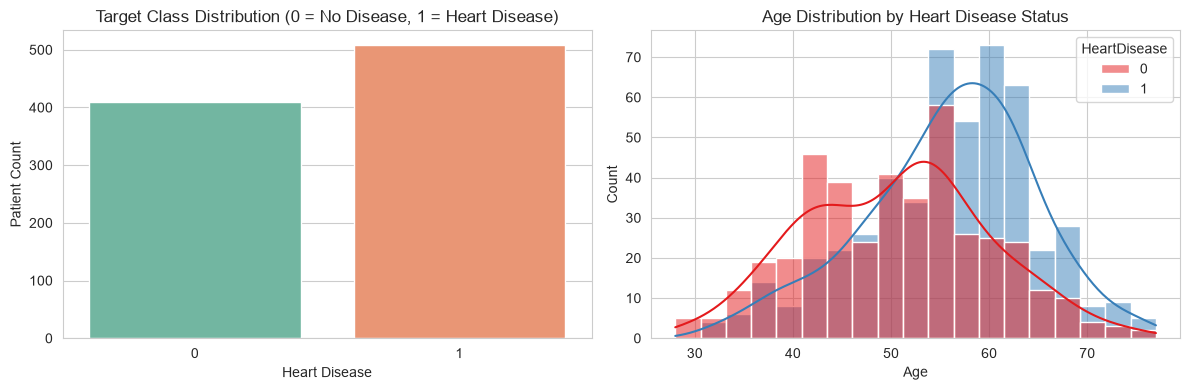

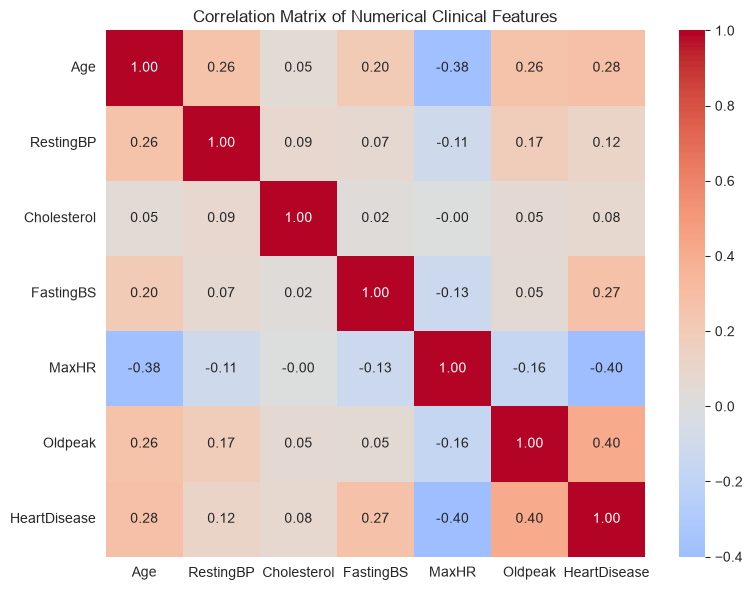

In [5]:
# Plot 1: Target distribution and Age distribution by Heart Disease status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df_clean, x='HeartDisease', hue='HeartDisease', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title("Target Class Distribution (0 = No Disease, 1 = Heart Disease)")
axes[0].set_xlabel("Heart Disease")
axes[0].set_ylabel("Patient Count")

sns.histplot(data=df_clean, x='Age', hue='HeartDisease', kde=True, palette='Set1', ax=axes[1])
axes[1].set_title("Age Distribution by Heart Disease Status")
plt.tight_layout()
plt.show()

# Plot 2: Correlation heatmap of numerical clinical features
plt.figure(figsize=(8, 6))
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numerical Clinical Features")
plt.tight_layout()
plt.show()

## 6. Feature Engineering, Encoding & Scaling Pipeline

In [6]:
# Separate predictor features (X) and target variable (y)
X = df_clean.drop(columns=['HeartDisease'])
y = df_clean['HeartDisease']

# Identify numerical and categorical columns
numeric_features = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
categorical_features = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# Build column transformer: StandardScaler for numerical, OneHotEncoder for categorical
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing pipeline configured successfully.")

Preprocessing pipeline configured successfully.


## 7. PCA Dimensionality Reduction Visualization (2D Class Separation)

Explained Variance Ratio by PC1 & PC2: [0.2591 0.1363]


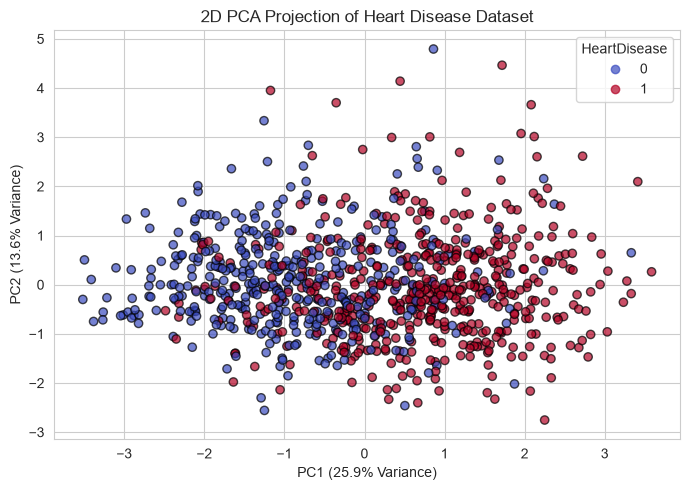

In [7]:
# Fit preprocessor and apply 2-component PCA to inspect feature separability
X_processed = preprocessor.fit_transform(X)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_processed)

print(f"Explained Variance Ratio by PC1 & PC2: {pca.explained_variance_ratio_.round(4)}")

plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', alpha=0.7, edgecolors='k')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.title("2D PCA Projection of Heart Disease Dataset")
plt.legend(*scatter.legend_elements(), title="HeartDisease")
plt.tight_layout()
plt.show()

## 8. Define Baseline Supervised ML Models

In [8]:
# Define three distinct supervised classification algorithms:
# 1. Logistic Regression (Linear baseline)
# 2. Random Forest Classifier (Tree-based ensemble)
# 3. Support Vector Machine (Kernel-based max-margin classifier)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(random_state=RANDOM_STATE)
}

## 9. Evaluate Accuracy Variation Across Three Splits (5%, 15%, 25%) with Cross-Validation

In [9]:
# Evaluate models across 5%, 15%, and 25% training splits using Stratified 5-Fold CV
splits = [0.05, 0.15, 0.25]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
split_results = []

for train_frac in splits:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, train_size=train_frac, stratify=y, random_state=RANDOM_STATE
    )
    for name, clf in models.items():
        pipe = Pipeline(steps=[('prep', preprocessor), ('model', clf)])
        
        # Cross-validation accuracy on the training split
        cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
        
        # Fit on training split and evaluate on unseen test split
        pipe.fit(X_train, y_train)
        train_acc = accuracy_score(y_train, pipe.predict(X_train))
        test_acc = accuracy_score(y_test, pipe.predict(X_test))
        
        split_results.append({
            "Train Split (%)": int(train_frac * 100),
            "Model": name,
            "Train Accuracy": round(train_acc, 4),
            "CV Mean Accuracy": round(cv_scores.mean(), 4),
            "CV Std": round(cv_scores.std(), 4),
            "Test Accuracy": round(test_acc, 4)
        })

results_df = pd.DataFrame(split_results)
display(results_df)

,Train Split (%),Model,Train Accuracy,CV Mean Accuracy,CV Std,Test Accuracy
0,5,Logistic Regression,0.9556,0.8444,0.1333,0.8041
1,5,Random Forest,1.0000,0.9111,0.1089,0.8064
2,5,SVM (RBF),0.9333,0.8667,0.1633,0.8133
3,15,Logistic Regression,0.8832,0.8542,0.0508,0.8361
4,15,Random Forest,1.0000,0.8913,0.0744,0.8387
5,15,SVM (RBF),0.9343,0.8399,0.0575,0.8195
6,25,Logistic Regression,0.8603,0.8254,0.0270,0.8403
7,25,Random Forest,1.0000,0.8471,0.0239,0.8476
8,25,SVM (RBF),0.8996,0.8603,0.0102,0.8389
